# Daily electricity consumption — rolling one-step-ahead forecasting

Compare five regression models against a **previous-day naive baseline** on daily German electricity consumption. Features include observed lags and calendar information. Chronological holdout and expanding-window cross-validation help avoid training on future dates.

**Forecasting setup:** the actual previous-day consumption is available before each new prediction. This is *not* a forecast of the entire test period made at once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_URL = "https://raw.githubusercontent.com/jenfly/opsd/refs/heads/master/opsd_germany_daily.csv"
data = pd.read_csv(DATA_URL, parse_dates=['Date']).sort_values('Date')
assert {'Date', 'Consumption'}.issubset(data.columns)
print(data[['Date', 'Consumption']].head())

        Date  Consumption
0 2006-01-01     1069.184
1 2006-01-02     1380.521
2 2006-01-03     1442.533
3 2006-01-04     1457.217
4 2006-01-05     1477.131


In [2]:
df = data[['Date', 'Consumption']].dropna().copy()
df['lag_1'] = df['Consumption'].shift(1)
df['lag_2'] = df['Consumption'].shift(2)
df['lag_7'] = df['Consumption'].shift(7)
df['day_of_week'] = df['Date'].dt.dayofweek
df['month'] = df['Date'].dt.month
df = df.dropna().reset_index(drop=True)
features = ['lag_1', 'lag_2', 'lag_7', 'day_of_week', 'month']
cutoff = int(len(df) * 0.8)
train, test = df.iloc[:cutoff], df.iloc[cutoff:]
X_train, y_train = train[features], train['Consumption']
X_test, y_test = test[features], test['Consumption']
print(f'Train: {len(train)}, test: {len(test)}; test dates: {test.Date.min().date()} to {test.Date.max().date()}')

Train: 3500, test: 876; test dates: 2015-08-09 to 2017-12-31


In [3]:
# Naive benchmark: predict today's consumption using yesterday's observed value.
# This is evaluated on the same held-out days as the ML models.
naive_pred = X_test['lag_1'].to_numpy()
rows = [{'model': 'Naive (previous day)', 'cv_mae': np.nan,
         'test_mae': mean_absolute_error(y_test, naive_pred),
         'test_rmse': np.sqrt(mean_squared_error(y_test, naive_pred)),
         'test_r2': r2_score(y_test, naive_pred)}]
predictions = {'Naive (previous day)': naive_pred}

models = {
    'Linear Regression': LinearRegression(),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=7)),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'SVR': make_pipeline(StandardScaler(), SVR()),
    # A convergence warning may occur; this model is included as a comparison,
    # not claimed to be optimized.
    'MLP': make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32,), max_iter=500, random_state=42)),
}
cv = TimeSeriesSplit(n_splits=5)
for name, estimator in models.items():
    cv_mae = -cross_val_score(estimator, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error').mean()
    fitted = clone(estimator).fit(X_train, y_train)
    pred = fitted.predict(X_test)
    predictions[name] = pred
    rows.append({'model': name, 'cv_mae': cv_mae,
                 'test_mae': mean_absolute_error(y_test, pred),
                 'test_rmse': np.sqrt(mean_squared_error(y_test, pred)),
                 'test_r2': r2_score(y_test, pred)})
results = pd.DataFrame(rows).sort_values('test_mae')
display(results.round(3))

# Choose an ML estimator by training-only CV, never by the holdout scores.
selected = min(models, key=lambda name: results.set_index('model').loc[name, 'cv_mae'])
print(f'Selected ML model by cross-validation: {selected}')
print('Compare its test MAE with the naive benchmark in the table above.')

,model,cv_mae,test_mae,test_rmse,test_r2
3,Random Forest,32.518,22.803,41.166,0.935
2,KNN,35.841,25.675,45.145,0.921
1,Linear Regression,44.249,43.916,61.829,0.852
4,SVR,74.656,52.995,78.702,0.761
5,MLP,497.422,99.476,127.187,0.376
0,Naive (previous day),NaN,101.663,149.231,0.141


Selected ML model by cross-validation: Random Forest
Compare its test MAE with the naive benchmark in the table above.


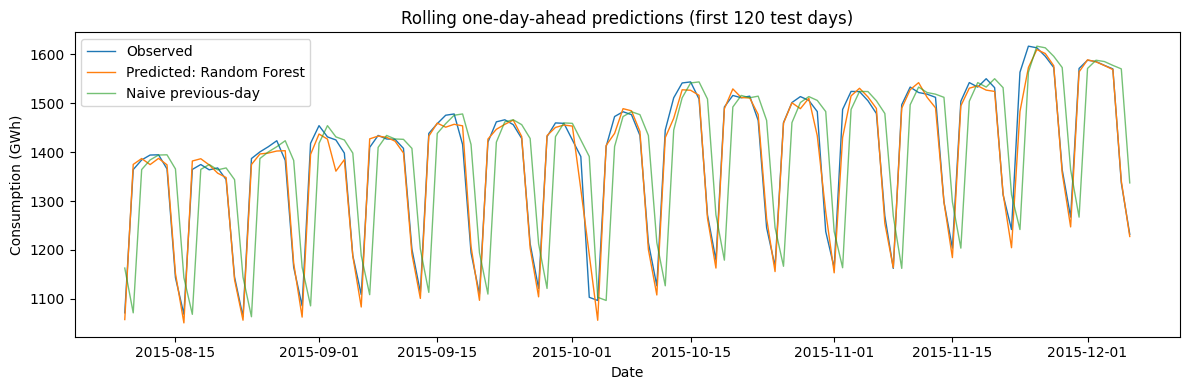

In [4]:
# Show a readable window of the held-out period (full holdout is scored above).
plot_days = min(120, len(test))
plt.figure(figsize=(12, 4))
plt.plot(test['Date'].iloc[:plot_days], y_test.to_numpy()[:plot_days], label='Observed', linewidth=1)
plt.plot(test['Date'].iloc[:plot_days], predictions[selected][:plot_days], label=f'Predicted: {selected}', linewidth=1)
plt.plot(test['Date'].iloc[:plot_days], naive_pred[:plot_days], label='Naive previous-day', alpha=0.65, linewidth=1)
plt.title('Rolling one-day-ahead predictions (first 120 test days)')
plt.xlabel('Date')
plt.ylabel('Consumption (GWh)')
plt.legend()
plt.tight_layout()
plt.show()

## Interpretation and limitations

- **Benchmark:** the previous-day naive baseline provides a reference. The ML approach should not be described as an improvement unless its held-out MAE is lower.
- **Validation:** five-fold expanding-window `TimeSeriesSplit` is applied to training data; the final test period remains untouched during model selection.
- **Forecast horizon:** test lag features include actual prior-day observations, so this is rolling **one-step-ahead** evaluation, not a multi-month forecast produced on a single date.
- **Model caveats:** MLP may emit `ConvergenceWarning` at 500 iterations; its hyperparameters have not been tuned. CV scores for the naive baseline are intentionally not reported.
- **Data:** external CSV must remain accessible. A working network connection is needed for the first cell.